# 1. Import Necessary Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering
from sklearn.preprocessing import StandardScaler

# 2. Data Collection

In [53]:
college_data = pd.read_csv(filepath_or_buffer="data/college_list.csv")
college_data.head()

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,Indian Institute of Technology Madras - Campus 1,14,113042,59,9.20,8
1,National Institute of Technology Trichy - Camp...,27,115999,67,3.07,7
2,Anna University Chennai - Campus 1,22,47955,50,3.40,9
3,PSG College of Technology - Campus 1,18,67841,43,4.64,8
4,Coimbatore Institute of Technology - Campus 1,15,100640,54,4.66,9


# 3. Data Understanding

In [54]:
college_data.shape

(500, 6)

In [55]:
college_data.isna().sum()

College_Name             0
Student_Faculty_Ratio    0
Annual_Fees_INR          0
Placement_Percentage     0
Average_Package_LPA      0
Infrastructure_Score     0
dtype: int64

In [56]:
college_data.duplicated().sum()

np.int64(0)

In [57]:
college_data.dtypes

College_Name                 str
Student_Faculty_Ratio      int64
Annual_Fees_INR            int64
Placement_Percentage       int64
Average_Package_LPA      float64
Infrastructure_Score       int64
dtype: object

In [58]:
college_data.College_Name.unique().tolist()

['Indian Institute of Technology Madras - Campus 1',
 'National Institute of Technology Trichy - Campus 1',
 'Anna University Chennai - Campus 1',
 'PSG College of Technology - Campus 1',
 'Coimbatore Institute of Technology - Campus 1',
 'Government College of Technology Coimbatore - Campus 1',
 'SSN College of Engineering - Campus 1',
 'SRM Institute of Science and Technology - Campus 1',
 'VIT Vellore - Campus 1',
 'SASTRA University - Campus 1',
 'Sri Sairam Engineering College - Campus 1',
 'Velammal Engineering College - Campus 1',
 'Rajalakshmi Engineering College - Campus 1',
 'St Josephs College of Engineering - Campus 1',
 'Kumaraguru College of Technology - Campus 1',
 'Thiagarajar College of Engineering - Campus 1',
 'Bannari Amman Institute of Technology - Campus 1',
 'Sri Krishna College of Engineering and Technology - Campus 1',
 'Sona College of Technology - Campus 1',
 'Karpagam College of Engineering - Campus 1',
 'Muthayammal Engineering College - Campus 1',
 'Paavai

In [59]:
college_data.describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
count,500.000000,500.000000,500.000000,500.000000,500.00000
mean,18.084000,138763.710000,69.000000,6.991720,5.97600
std,6.683283,63928.678815,17.193465,2.917991,2.00486
min,8.000000,30404.000000,40.000000,2.000000,3.00000
25%,12.000000,82610.500000,53.750000,4.472500,4.00000
50%,18.000000,140290.500000,69.000000,7.155000,6.00000
75%,24.000000,193422.000000,84.000000,9.432500,8.00000
max,29.000000,249930.000000,99.000000,11.990000,9.00000


# 4. Data Preperation

#### 4.1 Delete Unneccssary Features

In [60]:
X = college_data.drop(labels=["College_Name"], axis=1)

In [63]:
X_features = X.columns
X_features

Index(['Student_Faculty_Ratio', 'Annual_Fees_INR', 'Placement_Percentage',
       'Average_Package_LPA', 'Infrastructure_Score'],
      dtype='str')

#### 4.2 Apply Data Transformation Techniques

In [65]:
std_scalar = StandardScaler()
X_scaled = pd.DataFrame(std_scalar.fit_transform(X), columns=X_features)
X_scaled

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score
0,-0.611689,-0.402753,-0.582199,0.757539,1.010558
1,1.335411,-0.356452,-0.116440,-1.345326,0.511270
2,0.586526,-1.421892,-1.106178,-1.232121,1.509845
3,-0.012581,-1.110515,-1.513717,-0.806745,1.010558
4,-0.461912,-0.596945,-0.873298,-0.799884,1.509845
...,...,...,...,...,...
495,-0.162358,-0.507960,-0.756858,0.802135,-0.487305
496,-0.911243,-1.560372,0.407539,-1.156651,0.511270
497,-0.312135,0.946035,-0.291099,-1.067459,-1.485880
498,-1.210797,-1.446412,0.465759,0.795274,0.011983


In [69]:
X_scaled.mean().round(2)

Student_Faculty_Ratio    0.0
Annual_Fees_INR          0.0
Placement_Percentage    -0.0
Average_Package_LPA      0.0
Infrastructure_Score    -0.0
dtype: float64

In [70]:
X_scaled.std().round(2)

Student_Faculty_Ratio    1.0
Annual_Fees_INR          1.0
Placement_Percentage     1.0
Average_Package_LPA      1.0
Infrastructure_Score     1.0
dtype: float64

# 5. Model Building

### Step 1: Let's Check DENDOGRAM

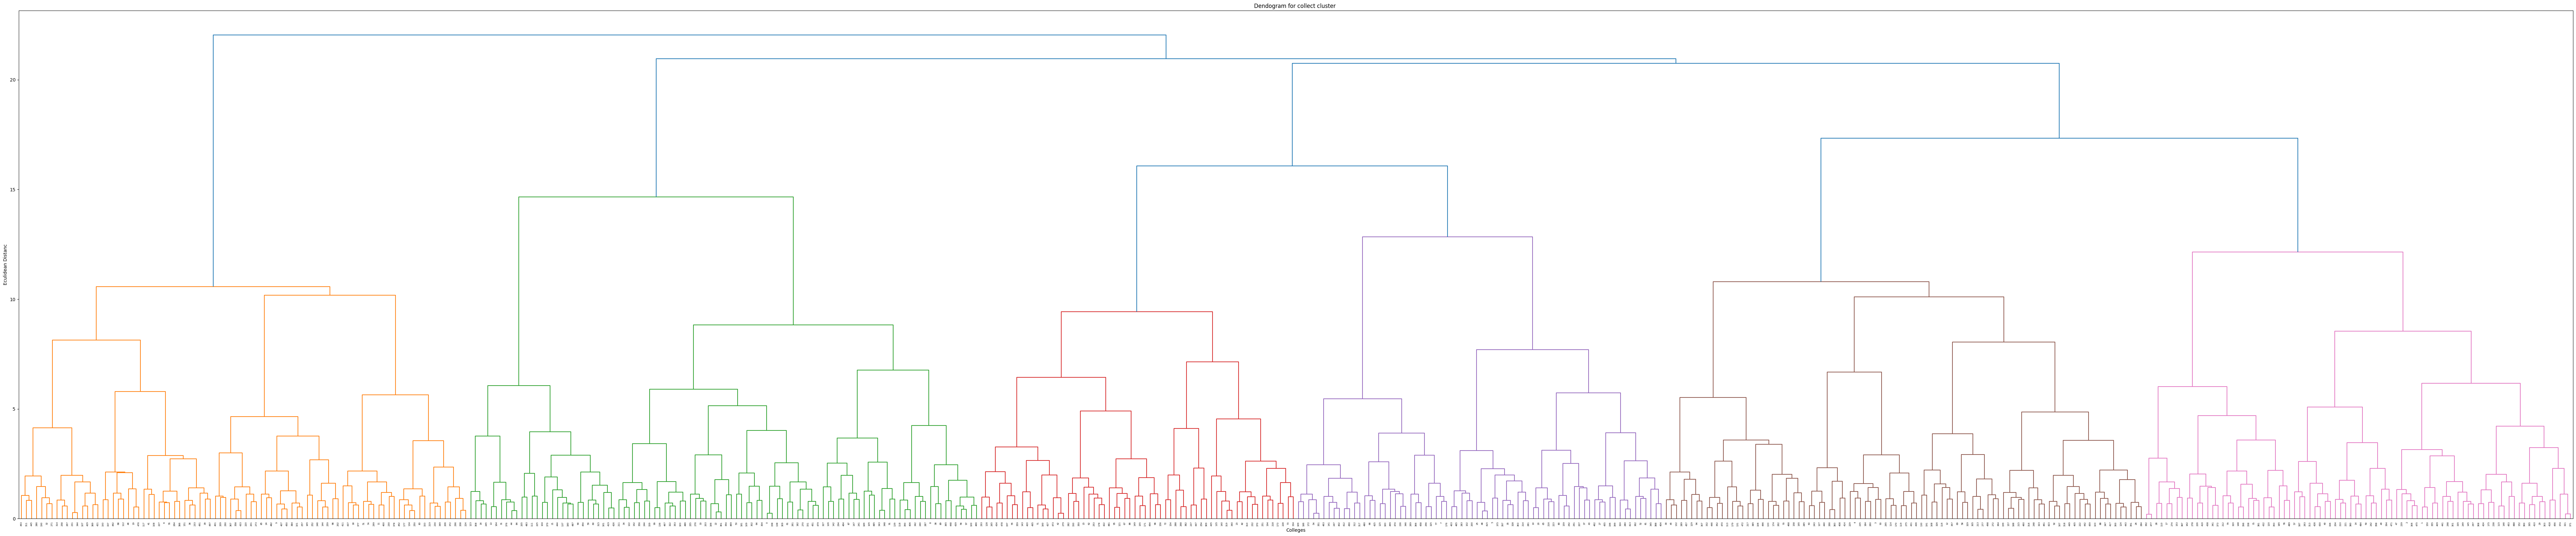

In [76]:
plt.figure(figsize=(100, 20))
dendogram = sch.dendrogram(sch.linkage(X_scaled, method="ward"))
plt.title("Dendogram for collect cluster ")
plt.xlabel("Colleges")
plt.ylabel("Eculidean Distanc")
plt.show()

for understanding take onoy 20 records

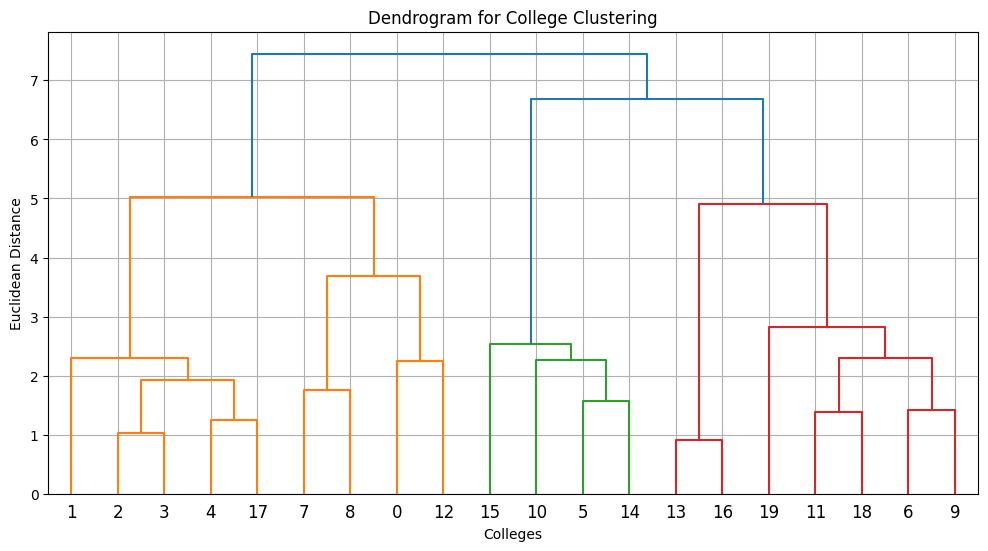

In [89]:
test_X = X_scaled.head(20)
plt.figure(figsize=(12,6))
dendrogram = sch.dendrogram(sch.linkage(test_X, method='ward'))
plt.title("Dendrogram for College Clustering")
plt.xlabel("Colleges")
plt.ylabel("Euclidean Distance")
plt.grid(True)
plt.show()


In [90]:
# import matplotlib.pyplot as plt
# import scipy.cluster.hierarchy as sch

# test_X = X_scaled.head(20)

# Z = sch.linkage(test_X, method='ward')

# plt.figure(figsize=(14, 7))

# dendro = sch.dendrogram(
#     Z,
#     labels=test_X.index.astype(str),
#     leaf_rotation=0
# )

# # Mark exact cluster merging positions
# for i, (icoord, dcoord) in enumerate(
#     zip(dendro['icoord'], dendro['dcoord'])
# ):

#     # Centre of the two joining branches
#     x = (icoord[1] + icoord[2]) / 2

#     # Height of the merge
#     y = dcoord[1]

#     plt.scatter(x, y, color='red', s=35, zorder=5)

#     plt.annotate(
#         f'{y:.2f}',
#         (x, y),
#         xytext=(5, 5),
#         textcoords='offset points',
#         fontsize=8,
#         color='red'
#     )

# plt.title("Dendrogram with Exact Merge Points")
# plt.xlabel("Colleges")
# plt.ylabel("Euclidean Distance")
# plt.grid(axis='y', alpha=0.3)
# plt.show()

### Step 2: Apply Aggloererative Clustering (Base don dendogram assume 3 cluster)

In [93]:
hc_model = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
hc_model

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'ward'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [95]:
clusters = hc_model.fit_predict(X_scaled)
clusters

array([2, 0, 0, 0, 0, 0, 1, 0, 2, 1, 0, 1, 0, 2, 0, 0, 2, 0, 1, 1, 0, 2,
       2, 0, 1, 0, 0, 0, 0, 0, 0, 2, 1, 2, 2, 0, 1, 0, 2, 1, 0, 1, 0, 0,
       2, 0, 1, 0, 0, 0, 0, 1, 0, 2, 0, 0, 2, 0, 0, 2, 2, 2, 0, 0, 2, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 2, 1, 0, 2,
       0, 2, 2, 2, 0, 0, 0, 0, 0, 2, 1, 2, 2, 1, 0, 0, 2, 2, 0, 1, 1, 2,
       0, 2, 1, 0, 0, 0, 0, 1, 2, 0, 0, 0, 2, 2, 0, 0, 2, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 2, 2, 2, 2, 0, 0, 2, 0, 1, 0, 0, 2, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 2, 0, 2, 2, 1, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 2, 2, 2, 0, 0, 0, 0, 0, 0, 2, 1, 0, 2, 1, 0, 0, 0, 0,
       2, 0, 0, 1, 1, 2, 0, 2, 1, 0, 1, 1, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 0, 0, 0, 1, 2, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 2, 2,
       0, 0, 2, 2, 1, 0, 0, 0, 1, 0, 1, 0, 0, 2, 0, 1, 1, 1, 0, 2, 0, 0,
       1, 0, 0, 1, 0, 0, 2, 1, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 2, 0, 0, 1, 0, 0, 0, 2, 0, 1, 0, 0, 1, 0,

##### Cluster is DONE here. Let's put this back to the original Dataset for further Data Mining Operations

# ===========================================================================================================

# Level 2: Attach Cluster to Datset 
- mainly naming for the classified clusters

In [146]:
college_data["College_Level"] = clusters
college_data.sample(10)

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
260,Muthayammal Engineering College - Campus 9,11,68765,54,5.72,8,0
235,Dhanalakshmi Srinivasan Engineering College - ...,14,105880,48,2.18,9,0
28,SNS College of Technology - Campus 1,22,149180,72,3.35,8,0
143,Nandha Engineering College - Campus 5,20,64620,54,11.89,5,0
92,Anna University Chennai - Campus 4,15,118092,76,7.30,5,0
120,Indian Institute of Technology Madras - Campus 5,22,153961,54,5.36,8,0
431,Velammal Engineering College - Campus 15,12,103688,59,2.97,7,0
321,Paavai College of Engineering - Campus 11,28,100390,71,6.65,4,0
80,Muthayammal Engineering College - Campus 3,25,238124,73,6.22,5,0
195,Thiagarajar College of Engineering - Campus 7,9,87043,82,7.16,8,0


### Data Mining 

In [148]:
college_data[college_data.College_Level == 0].describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
count,312.000000,312.000000,312.000000,312.000000,312.000000,312.0
mean,20.407051,121853.471154,67.278846,6.954583,6.509615,0.0
std,6.221864,62742.503073,16.421766,2.915805,1.861759,0.0
min,8.000000,30404.000000,40.000000,2.000000,3.000000,0.0
25%,15.000000,67816.750000,53.000000,4.530000,5.000000,0.0
50%,21.500000,110953.000000,67.000000,6.990000,7.000000,0.0
75%,26.000000,167934.000000,79.000000,9.335000,8.000000,0.0
max,29.000000,249536.000000,99.000000,11.990000,9.000000,0.0


In [149]:
college_data[college_data.College_Level == 1].describe()

,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level
count,88.000000,88.000000,88.000000,88.000000,88.000000,88.0
mean,17.159091,156795.136364,85.568182,5.565682,3.965909,1.0
std,6.102357,58118.713158,8.140710,2.675847,1.217203,0.0
min,8.000000,39337.000000,64.000000,2.090000,3.000000,1.0
25%,12.000000,109282.250000,79.750000,3.317500,3.000000,1.0
50%,16.500000,166776.000000,86.000000,4.775000,4.000000,1.0
75%,23.000000,199720.000000,93.000000,7.347500,4.000000,1.0
max,29.000000,248803.000000,99.000000,11.960000,9.000000,1.0


In [153]:
college_data.columns

Index(['College_Name', 'Student_Faculty_Ratio', 'Annual_Fees_INR',
       'Placement_Percentage', 'Average_Package_LPA', 'Infrastructure_Score',
       'College_Level'],
      dtype='str')

In [155]:
college_data.groupby("College_Level")[
    [
        "Student_Faculty_Ratio",
        "Annual_Fees_INR",
        "Placement_Percentage",
        "Average_Package_LPA",
        "Infrastructure_Score",
    ]
].agg(["mean", "min", "max"])

Student_Faculty_Ratio          ... Infrastructure_Score        
                               mean min max  ...                 mean min max
College_Level                                ...                             
0                         20.407051   8  29  ...             6.509615   3   9
1                         17.159091   8  29  ...             3.965909   3   9
2                         11.650000   8  20  ...             6.080000   3   9

[3 rows x 15 columns]

In [157]:
cluster_names = {
    1: "Best Colleges",
    2: "Mid-Level Colleges",
    0: "Emerging / Lower-Level Colleges",
}

college_data["Category"] = college_data["College_Level"].map(cluster_names)

In [178]:
college_data.sample(5)

,College_Name,Student_Faculty_Ratio,Annual_Fees_INR,Placement_Percentage,Average_Package_LPA,Infrastructure_Score,College_Level,Category
118,SNS College of Technology - Campus 4,10,170507,72,5.98,9,2,Mid-Level Colleges
381,Paavai College of Engineering - Campus 13,19,242890,62,6.70,6,0,Emerging / Lower-Level Colleges
443,Nandha Engineering College - Campus 15,11,164668,69,7.99,5,0,Emerging / Lower-Level Colleges
74,Kumaraguru College of Technology - Campus 3,15,133150,89,6.73,3,1,Best Colleges
253,St Josephs College of Engineering - Campus 9,27,40916,62,8.76,4,0,Emerging / Lower-Level Colleges


# Level 3: Now it's time to Transition to Sueprvised learning

- use any of the supervised algorithm to train the current data with the output feature
- for `X` remove the `College_Name, College_LeveL and "Category"` and use `College_leve` as `y`

# THE END!!!